# Imports

In [167]:
# Get imports and functions needed
%run BaseFiles/Imports.ipynb
%run BaseFiles/Functions.ipynb

# Set global variables
colour1 = "royalblue"
colour2 = "red"
colour3 = "goldenrod"

# Read data from files

In [168]:
# Places to get and save files
DataDirectory = "Data/windData/"
dataName = "wind_min_b"
PlotDirectory = "Plots/WindYearlyPlots/"

# Details: Yearly, minutely data, bow-shock shifted

In [169]:
# Variables
DataSource = "Wind"

TimeFrames = [["1996-01-01 00:00","1996-02-01 00:00"], ["1996-1-01 00:00", "1997-01-01 00:00"], ["2001-01-01 00:00", "2002-01-01 00:00"] ] # Basic, Maximum, Minimum
# Basic
# # Start  = "1996-01-01 00:00"
# # End = "1996-02-01 00:00"
# Minimum
# # Start  = "1996-06-01 00:00"
# # End = "1996-07-01 00:00"
# Maximum
# # Start  = "2001-06-01 00:00"
# # End = "2001-12-01 00:00"



# Read data to dataframes

In [170]:
dataTimeSerieses = [[],[],[]] # empty array for data

for j in range(len(TimeFrames)):
    Start = TimeFrames[j][0]
    End = TimeFrames[j][1]
    #Separated by data source as files may have different file name conventions
    if DataSource == "Wind": # If WIND data
        YearlyRange = Yearly(Start, End, frequency = 'MS') #Get range of dates needed # changed to monthly
        print(YearlyRange)
        # dataTimeSerieses = [] # empty array for data
        # StartAndEnd = [] # empty array for start and end times
        for i in range(len(YearlyRange)-1): # for each date range in time range needed
            StartDate = YearlyRange[i] # first file in range
            if YearlyRange[i][4:6] == "01" or YearlyRange[i][4:6] == "03" or YearlyRange[i][4:6] == "05" or YearlyRange[i][4:6] == "07" or YearlyRange[i][4:6] == "08" or YearlyRange[i][4:6] == "10" or YearlyRange[i][4:6] == "12":
                EndDate = YearlyRange[i][0:6] + "31" # last file in range
            elif YearlyRange[i][4:6] == "02":
                if YearlyRange[i][0:4] == "2000" or YearlyRange[i][0:4] == "2008" or YearlyRange[i][0:4] == "2016" or YearlyRange[i][0:4] == "2024":
                    EndDate = YearlyRange[i][0:6] + "29" # last file in range
                else:
                    EndDate = YearlyRange[i][0:6] + "28" # last file in range
            elif YearlyRange[i][4:6] == "04" or YearlyRange[i][4:6] == "06" or YearlyRange[i][4:6] == "09" or YearlyRange[i][4:6] == "11":
                EndDate = YearlyRange[i][0:6] + "30" # last file in range            
            # print(StartDate, EndDate)
            # DateRange = ReadDates(StartDate, EndDate) # get date range
            dataFound = FindDataWind(DataDirectory, dataName, StartDate, EndDate) # find data
            dataTS = dfToSeries(dataFound) # convert to timeseries
            dataTS = AddTotVsw(dataTS) # add totvsw
            dataTS = AddBMag(dataTS) # add bmag
            # dataTS = AddLogBMag(dataTS) 
            # dataTS = AddLogBX(dataTS)
            dataTimeSerieses[j].append(dataTS) # add to data array
            # StartAndEnd.append([StartDate, EndDate]) # add start and end dates to times array

    else: # if not wind (or other coded sources)
        print("Data source not known") # give error message


['19960101', '19960201']
['19960101', '19960201', '19960301', '19960401', '19960501', '19960601', '19960701', '19960801', '19960901', '19961001', '19961101', '19961201', '19970101']
['20010101', '20010201', '20010301', '20010401', '20010501', '20010601', '20010701', '20010801', '20010901', '20011001', '20011101', '20011201', '20020101']


In [171]:
# print(dataTimeSerieses)
# print(len(dataTimeSerieses))
# print(dataTimeSerieses[2])

# combined_goes_ts = dataTimeSerieses[0].concatenate(dataTimeSerieses[1])


In [172]:
def resampleMean(data, rate, label = "right"):
    resampled = data.resample(rate, label=label).mean()
    resampledTS = TimeSeries(resampled)
    return resampledTS

In [173]:
# print(dataTimeSerieses[1][1])
for i in range(len(dataTimeSerieses)):
    # print(i)
    for j in range(len(dataTimeSerieses[i])):
        # print(j)
        dataTimeSerieses[i][0] = dataTimeSerieses[i][0].concatenate(dataTimeSerieses[i][j])
    
    # print(dataTimeSerieses[i][0])

dataTSConcat = [dataTimeSerieses[0][0], dataTimeSerieses[1][0], dataTimeSerieses[2][0]]


# Remove CMEs

## Get CME start and end dates

In [174]:
from datetime import datetime
from datetime import date, timedelta
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np 

import pandas as pd
url='https://helioforecast.space/static/sync/icmecat/HELIO4CAST_ICMECAT_v23.csv'
ic=pd.read_csv(url)
ic.keys()

ic = ic.truncate(before=0, after=1901) # get from current most recent (2025-08-10) back to beginning of 1996



## Only Wind ICMEs

In [175]:
WindOnly = ic.loc[ic['sc_insitu'] == "Wind"]   # create a wind only dataframe
WindOnly.insert(0, "Index", range(0, len(WindOnly.icme_start_time)))   # set the indexes to be 0,1,2,3, etc. instead of the original event indexes
WindOnly.set_index("Index", inplace = True)

print(WindOnly.icme_start_time)
print(WindOnly.sc_insitu)

Index
0      2025-07-26T16:44Z
1      2025-07-03T04:52Z
2      2025-06-12T19:34Z
3      2025-06-07T00:12Z
4      2025-06-04T13:44Z
             ...        
535    1996-07-01T13:05Z
536    1996-05-27T14:45Z
537    1996-05-16T22:47Z
538    1996-04-04T11:59Z
539    1996-02-15T15:07Z
Name: icme_start_time, Length: 540, dtype: str
Index
0      Wind
1      Wind
2      Wind
3      Wind
4      Wind
       ... 
535    Wind
536    Wind
537    Wind
538    Wind
539    Wind
Name: sc_insitu, Length: 540, dtype: str


## Get start and end dates

In [176]:
print(WindOnly.icme_start_time)

ICMETimes = []
for i in range(len(WindOnly.icme_start_time)):
    StartTime = datetime.fromisoformat(WindOnly.icme_start_time[i])-timedelta(hours=12)
    # print(datetime.fromisoformat(WindOnly.icme_start_time[i]))
    # print(StartTime)
    EndTime = datetime.fromisoformat(WindOnly.mo_end_time[i])+timedelta(hours=12)
    ICMETimes.append([StartTime.replace(tzinfo=None), EndTime.replace(tzinfo=None)])

print(ICMETimes[:])

# dt = ICMETimes[0][].replace(tzinfo=None)
# print(dt)

Index
0      2025-07-26T16:44Z
1      2025-07-03T04:52Z
2      2025-06-12T19:34Z
3      2025-06-07T00:12Z
4      2025-06-04T13:44Z
             ...        
535    1996-07-01T13:05Z
536    1996-05-27T14:45Z
537    1996-05-16T22:47Z
538    1996-04-04T11:59Z
539    1996-02-15T15:07Z
Name: icme_start_time, Length: 540, dtype: str
[[datetime.datetime(2025, 7, 26, 4, 44), datetime.datetime(2025, 7, 28, 5, 40)], [datetime.datetime(2025, 7, 2, 16, 52), datetime.datetime(2025, 7, 5, 7, 6)], [datetime.datetime(2025, 6, 12, 7, 34), datetime.datetime(2025, 6, 13, 18, 2)], [datetime.datetime(2025, 6, 6, 12, 12), datetime.datetime(2025, 6, 8, 21, 28)], [datetime.datetime(2025, 6, 4, 1, 44), datetime.datetime(2025, 6, 5, 16, 38)], [datetime.datetime(2025, 6, 2, 8, 0), datetime.datetime(2025, 6, 4, 2, 52)], [datetime.datetime(2025, 6, 1, 15, 56), datetime.datetime(2025, 6, 2, 20, 4)], [datetime.datetime(2025, 6, 1, 6, 54), datetime.datetime(2025, 6, 2, 12, 32)], [datetime.datetime(2025, 6, 1, 0, 6), d

In [177]:
len(dataTSConcat[1].to_dataframe())

525290

## Remove the dates from the data

In [178]:
dataTSConcatNoCMEs = []
dataTSConcatOnlyCMEs = []
for i in range(len(dataTSConcat)):                              # for each dataset
    # print(len(dataTimeSerieses[i].to_dataframe()[i]))
    print(i)
    INDEX = np.ones(len(dataTSConcat[i].to_dataframe()))        # get ones array for tracking where CMEs are
    # INDEX = np.ones(len(dataTimeSerieses[i].to_dataframe()))
    for CME in ICMETimes:                                           # for each CME in the catalogue seen by Wind
        start = CME[0]                                              # get start time
        end = CME[1]                                                # get end time
        # print(start, end)
        ind = (dataTSConcat[i].to_dataframe().index < start) | (dataTSConcat[i].to_dataframe().index > end) # get 0 as an index for times that CME is present, get 1 for times it is not present
        # ind = np.where((dataTimeSerieses[0].to_dataframe().index < start) | (dataTimeSerieses[0].to_dataframe().index > end))
        # dfCMEsRemoved.where((dfCMEsRemoved.index > start) | (dfCMEsRemoved.index < end))
        # ind = dataTimeSerieses[0].to_dataframe().loc[(dataTimeSerieses[0].to_dataframe().index < start) & (dataTimeSerieses[0].to_dataframe().index > end)]
        # print(ind)
        # print(len(ind))
        INDEX = INDEX * ind                                         # Multiply the tracking array by the array for this CME s.t. the resulting array gets 0's for any times with CMEs and 1's for times without CMEs
    MapForINDEX = INDEX.astype(np.bool)                             # Change the 0/1 array to False/True
    dfCMEsRemoved = dataTSConcat[i].to_dataframe()[MapForINDEX] # Make a new year dataframe where the CMEs are removed
    # print(dfCMEsRemoved[64975:65000])
    dfCMEsRemoved = dfToSeries(dfCMEsRemoved)                                       # Make the data frame into a time series
    dataTSConcatNoCMEs.append(dfCMEsRemoved)                    # Amend the new Serieses array with the CME removed versions

    dfOnlyCMEs = dataTSConcat[i].to_dataframe()[~MapForINDEX] # Make a new year dataframe where the CMEs are present
    # print(dfCMEsRemoved[64975:65000])
    dfOnlyCMEs = dfToSeries(dfOnlyCMEs)                                       # Make the data frame into a time series
    dataTSConcatOnlyCMEs.append(dfOnlyCMEs)                    # Amend the new Serieses array with the CME present versions

print(dataTSConcatNoCMEs[0])
print(dataTSConcatNoCMEs[1])
print(dataTSConcatNoCMEs[2])

# print(dataTSConcatOnlyCMEs[0])

# print(len(ind[0]))
# print(index)
# #############
# #Separated by data source as files may have different file name conventions
# if DataSource == "Wind":
#     YearlyRange = Yearly(Start, End)
#     # print(YearlyRange)
#     dataTimeSerieses = []
#     StartAndEnd = []
#     for i in range(len(YearlyRange)-1):
#         StartDate = YearlyRange[i]
#         EndDate = YearlyRange[i][0:4] + "1231"
#         # print(StartDate, EndDate)
#         # DateRange = ReadDates(StartDate, EndDate) # get date range
#         dataFound = FindDataWind(DataDirectory, dataName, StartDate, EndDate) # find data
#         dataTS = dfToSeries(dataFound)
#         dataTS = AddTotVsw(dataTS) # add totvsw
#         dataTS = AddBMag(dataTS) # add bmag
#         dataTS = AddLogBMag(dataTS) 
#         dataTS = AddLogBX(dataTS)
#         dataTimeSerieses.append(dataTS)
#         StartAndEnd.append([StartDate, EndDate])

# else:
#     print("Data source not known")

#     # print(dataTimeSerieses)
#     # print(StartAndEnd)
# ##############

# # # Filter data between two dates
# filtered_df = df.loc[(df['date'] >= '2020-09-01')
#                      & (df['date'] < '2020-09-15')]

# print(len(INDEX))
# print(len(dataTimeSerieses[0].to_dataframe()))
# print(INDEX[524500:])
# print(np.unique(INDEX))

# MapForINDEX = INDEX.astype(np.bool)
# dfCMEsRemoved =  dataTimeSerieses[0].to_dataframe()[MapForINDEX]
# print(dfCMEsRemoved[64975:65000])


0
1
2
SunPy TimeSeries
----------------
Observatory:			Unknown
Instrument:			Unknown
Channel(s):			Year<br>DOY<br>Hour<br>Minute<br>IMF_PTS<br>PercentInterp<br>CP/MVFlag<br>Timeshift<br>PFN_XGSE<br>PFN_YGSE<br>PFN_ZGSE<br>ScalarB<br>Bx_GSEGSM<br>ByGSE<br>BzGSE<br>ByGSM<br>BzGSM<br>RMSTimeshift<br>RMS_PFN<br>RMSScalarB<br>RMSFieldVector<br>Plasma_PTS<br>FlowSpeed<br>Vx_GSE<br>Vy_GSE<br>Vz_GSE<br>ProtonDensity<br>Temp<br>X_s_c_GSE<br>Y_s_c_GSE<br>Z_s_c_GSE<br>X_targ_GSE<br>Y_targ_GSE<br>Z_targ_GSE<br>RMS_targ<br>DBOT1<br>DBOT2<br>TotVsw<br>BMag
Start Date:			1996-01-01 00:00:00
End Date:			1996-01-31 23:59:00
Center Date:			1996-01-16 11:59:30
Resolution:			59.999 s
Samples per Channel:		44640
Data Range(s):		Year             0.00E+00<br>DOY              3.00E+01<br>Hour             2.30E+01<br>Minute           5.90E+01<br>IMF_PTS          7.80E+01<br>PercentInterp    1.00E+02<br>CP/MVFlag        1.00E+00<br>Timeshift        6.36E+03<br>PFN_XGSE         8.90E-01<br>PFN_YGSE         1.92E

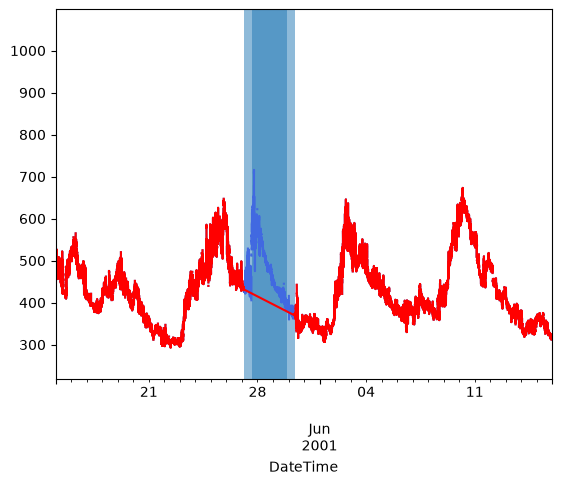

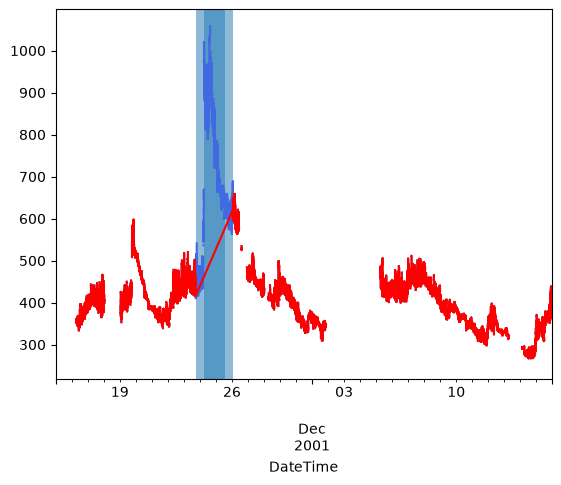

In [179]:
ds = dataTSConcat[2]
dsnc = dataTSConcatNoCMEs[2]
# dsoc = dataTimeSeriesesOnlyCMEs[21]
# CMEStart =  '2001-11-24 05:51' # [0] cme start time 2001-11-24 05:51
# CMEEnd = '2001-11-25 13:17' # mo end time 2001-11-25 13:17
# CMEStart =  '2001-10-31 13:46' # [0] cme start time 2001-10-31 13:46
# CMEEnd = '2001-11-02 04:47' # mo end time 2001-11-02 04:47
# CMEStart =  '2001-09-29 09:28' # [0] cme start time 2001-09-29 09:28
# CMEEnd = '2001-09-30 19:14' # mo end time 2001-09-30 19:14

ylim = [300,1000]

Alpha2 = 1
# ds.to_dataframe()["TotVsw"][350000:400000].plot(color = "royalblue", alpha=Alpha2)
# dsnc.to_dataframe()["TotVsw"][350000:400000].plot( color="red", alpha=Alpha2)
ds.to_dataframe()["TotVsw"].plot(color = "royalblue", alpha=Alpha2)
dsnc.to_dataframe()["TotVsw"].plot( color="red", alpha=Alpha2)
plt.xlim(['2001-05-15 00:00', '2001-06-15 23:00'])

plt.axvspan('2001-05-27 14:45', '2001-05-29 21:34', alpha=0.5)
plt.axvspan('2001-05-27 02:45', '2001-05-30 09:34', alpha=0.5)
plt.show()

# CMEStart =  '2001-11-24 05:51' # [0] cme start time 2001-11-24 05:51
# CMEEnd = '2001-11-25 13:17' # mo end time 2001-11-25 13:17
ds.to_dataframe()["TotVsw"].plot(color = "royalblue", alpha=Alpha2)
dsnc.to_dataframe()["TotVsw"].plot( color="red", alpha=Alpha2)
plt.xlim(['2001-11-15 00:00', '2001-12-15 23:00'])

plt.axvspan('2001-11-24 05:51', '2001-11-25 13:17', alpha=0.5)
plt.axvspan('2001-11-23 17:51', '2001-11-26 01:17', alpha=0.5)
plt.show()

# print("With CMEs")
# PlotVsw(TimeSeries(ds.truncate(CMEStart, CMEEnd)), XLim = [CMEStart, CMEEnd], Columns = ["TotVsw"], YLim = ylim)
# print("CMEs removed")
# PlotVsw(TimeSeries(dsnc.truncate(CMEStart, CMEEnd)), XLim = [CMEStart, CMEEnd], Columns = ["TotVsw"], YLim = ylim)
# print("Only CMEs")
# PlotVsw(TimeSeries(dsoc.truncate(CMEStart, CMEEnd)), XLim = [CMEStart, CMEEnd], Columns = ["TotVsw"], YLim = ylim)


In [180]:
# print(dataTSConcatNoCMEs[0])
# print(dataTSConcatNoCMEs[1])
# print(dataTSConcatNoCMEs[2])
dataTSConcat = [dataTSConcatNoCMEs[0], dataTSConcatNoCMEs[1], dataTSConcatNoCMEs[2]]


# Working on one month

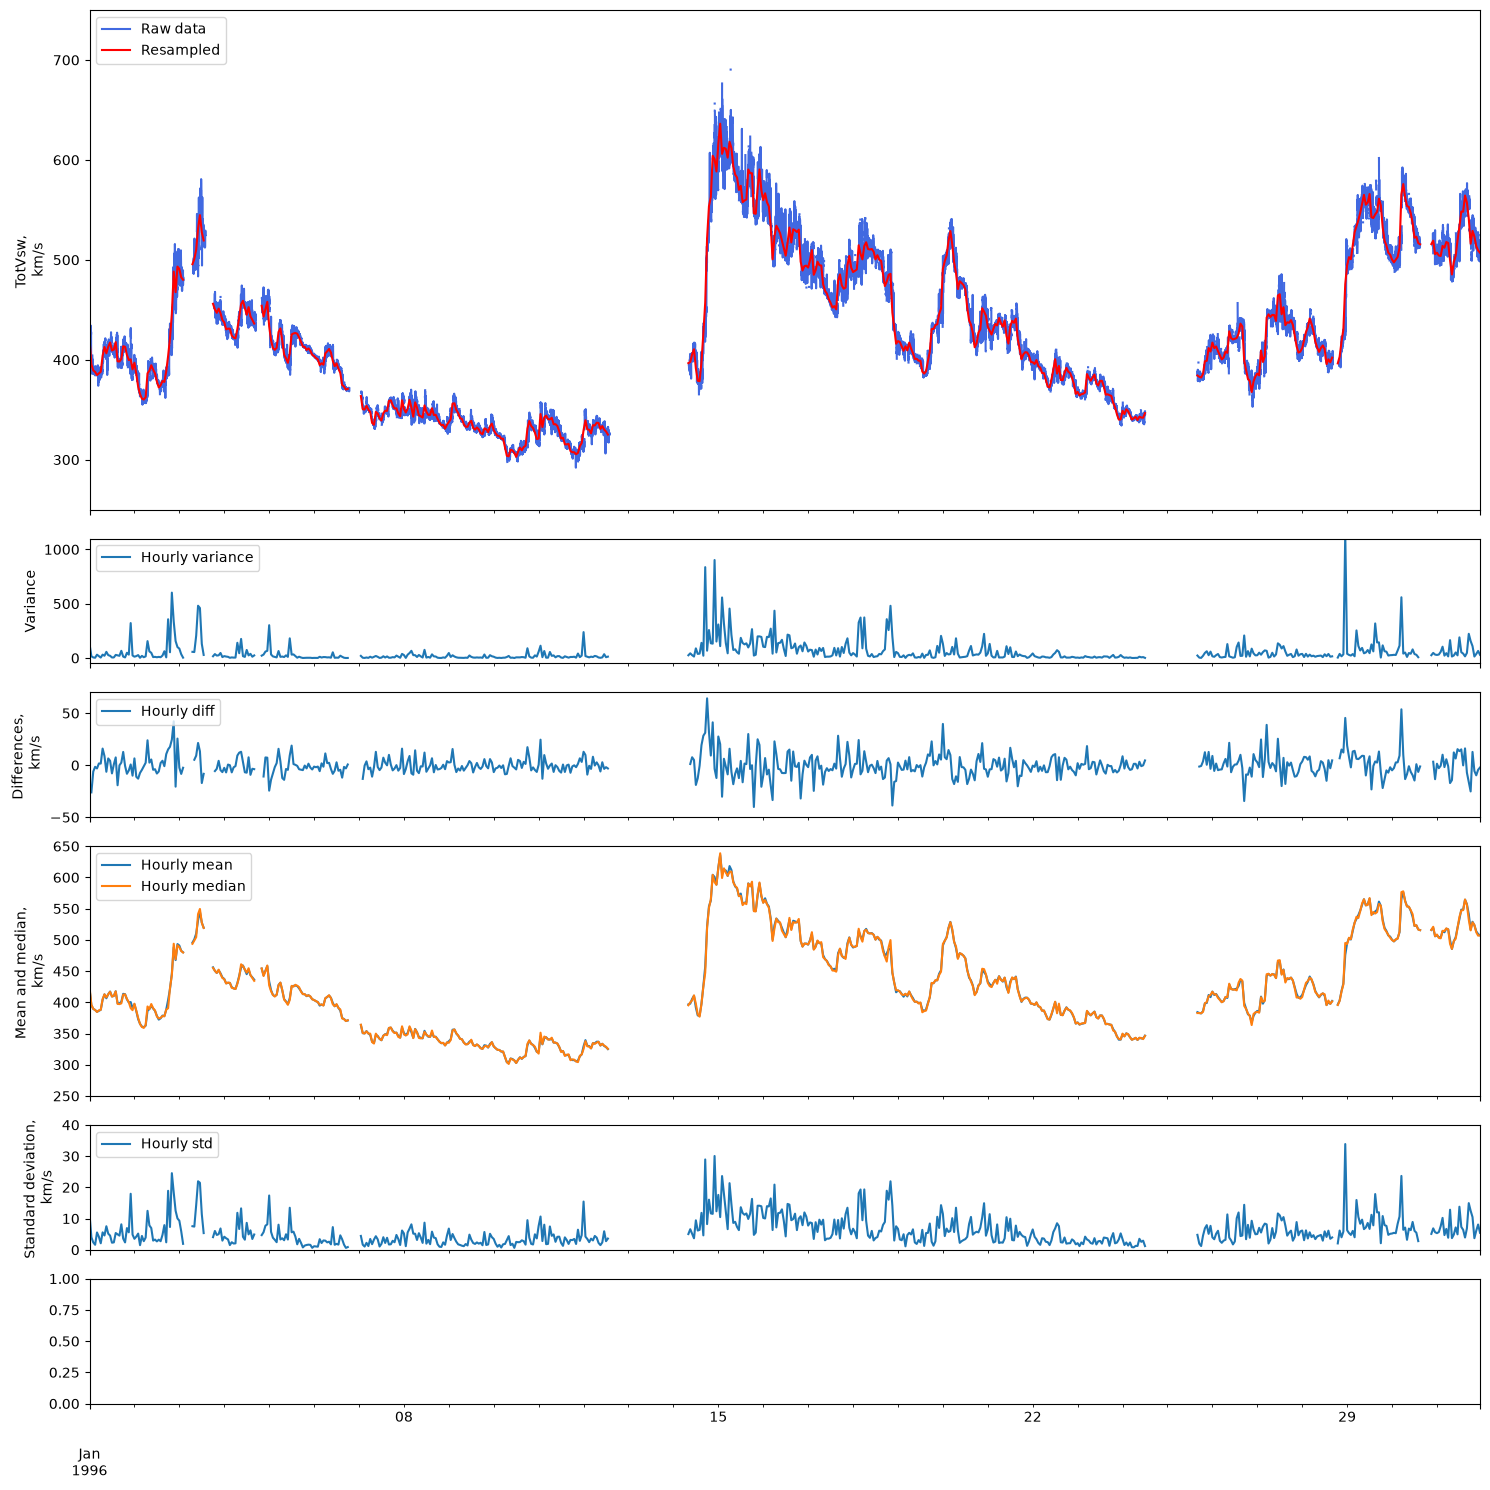

[3600.0, 32400.0, 7200.0, 7200.0, 10800.0, 3600.0, 3600.0, 7200.0, 18000.0, 3600.0, 3600.0, 18000.0, 7200.0, 3600.0, 3600.0, 3600.0, 3600.0, 3600.0, 7200.0, 7200.0, 3600.0, 10800.0, 3600.0]


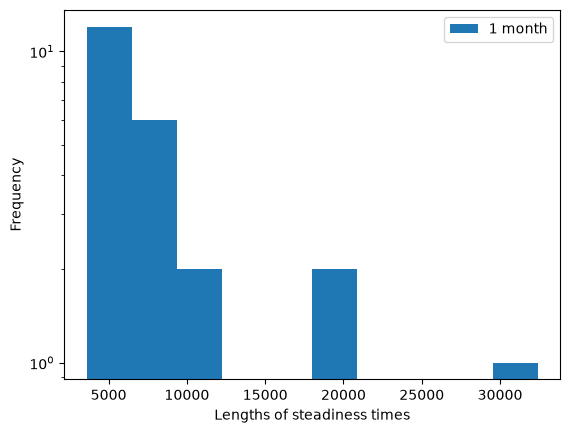

In [244]:
# TotVsw
Variable = "TotVsw"
Unit = "km/s"
YLim = [[250, 750],[-50, 1100],[-50, 70], [250, 650], [0, 40]]
Thres = 5

# # BMag
# Variable = "BMag"
# Unit = "nT"
# YLim = [[-1, 20],[-2, 10],[-5, 6], [0, 15], [0, 3]]
# Thres = 0.1


fig, axs = plt.subplots(6,1, sharex=True, height_ratios=[4,1,1,2,1,1], figsize=(15, 15))
rawData = dataTSConcat[0].to_dataframe()
# Resample data - Choose a resample rate that seems accurate to changes in data
# resampledRate1 = resampleMean(rawData, "1h").to_dataframe()
resampledRate1 = rawData.resample("1h").mean()

# Plot
# print(axs[0])
rawData[Variable].plot(color=colour1, label = "Raw data", ax=axs[0])
resampledRate1[Variable].plot(color=colour2, label = "Resampled", ax=axs[0])

# Variance
hourly_var = rawData[Variable].resample("1h").var()
hourly_var.plot(ax=axs[1], label="Hourly variance")

# Differences
hourly_diff = resampledRate1[Variable].diff()
hourly_diff.plot(ax=axs[2], label="Hourly diff")

# Mean/median/standard dev
hourly_mean = rawData[Variable].resample("1h").mean()
hourly_median = rawData[Variable].resample("1h").median()
hourly_mean.plot(ax=axs[3], label="Hourly mean")
hourly_median.plot(ax=axs[3], label="Hourly median")

hourly_std = rawData[Variable].resample("1h").std()
hourly_std.plot(ax=axs[4], label="Hourly std")

# Steadiness defn.
mask_var = hourly_var.between(0, Thres)

values = hourly_var.reindex(mask_var.index)
valid = mask_var.fillna(False).astype(bool) & values.notna()

# print(hourly_var)
# print(mask_var)
# print(values)
# print(valid)

is_start = valid & ~valid.shift(1, fill_value=False)
is_end = valid & ~valid.shift(-1, fill_value=False)

StartsPossible = valid.index[is_start].tolist()
EndsPossible = valid.index[is_end].tolist()

# print(len(StartsPossible))
# print(len(EndsPossible))
# print(StartsPossible)
# print(EndsPossible)

Starts = []
Ends = []
for i in range(len(StartsPossible)):
    # if StartsPossible[i] == EndsPossible[i]:
        # print("Same")
    if StartsPossible[i] != EndsPossible[i]:
        Starts.append(StartsPossible[i])
        Ends.append(EndsPossible[i])

for j in range(len(Starts)):
    axs[5].axvspan(Starts[j], Ends[j], color="goldenrod", alpha = 0.7)
    
# print(len(Starts))
# print(len(Ends))
# print(Starts)
# print(Ends)

# Starts = StartsPossible.copy()
# Ends = EndsPossible.copy()

YLabel = [ Variable+ ", \n" + Unit, "Variance", "Differences, \n " + Unit, "Mean and median, \n" + Unit, "Standard deviation, \n" + Unit]
for i in range(0,5):
    axs[i].legend(loc="upper left")
    axs[i].set_ylim(YLim[i])
    axs[i].set_ylabel(YLabel[i])



plt.tight_layout()
plt.show()

Taus1Month = []
for i in range(len(Starts)):
    Taus1Month.append((Ends[i] - Starts[i]).total_seconds())

print(Taus1Month)

plt.hist(Taus1Month, bins=10, label = "1 month")
plt.yscale('log')
plt.ylabel("Frequency")
plt.xlabel("Lengths of steadiness times")
plt.legend()
plt.show()

# Minimum

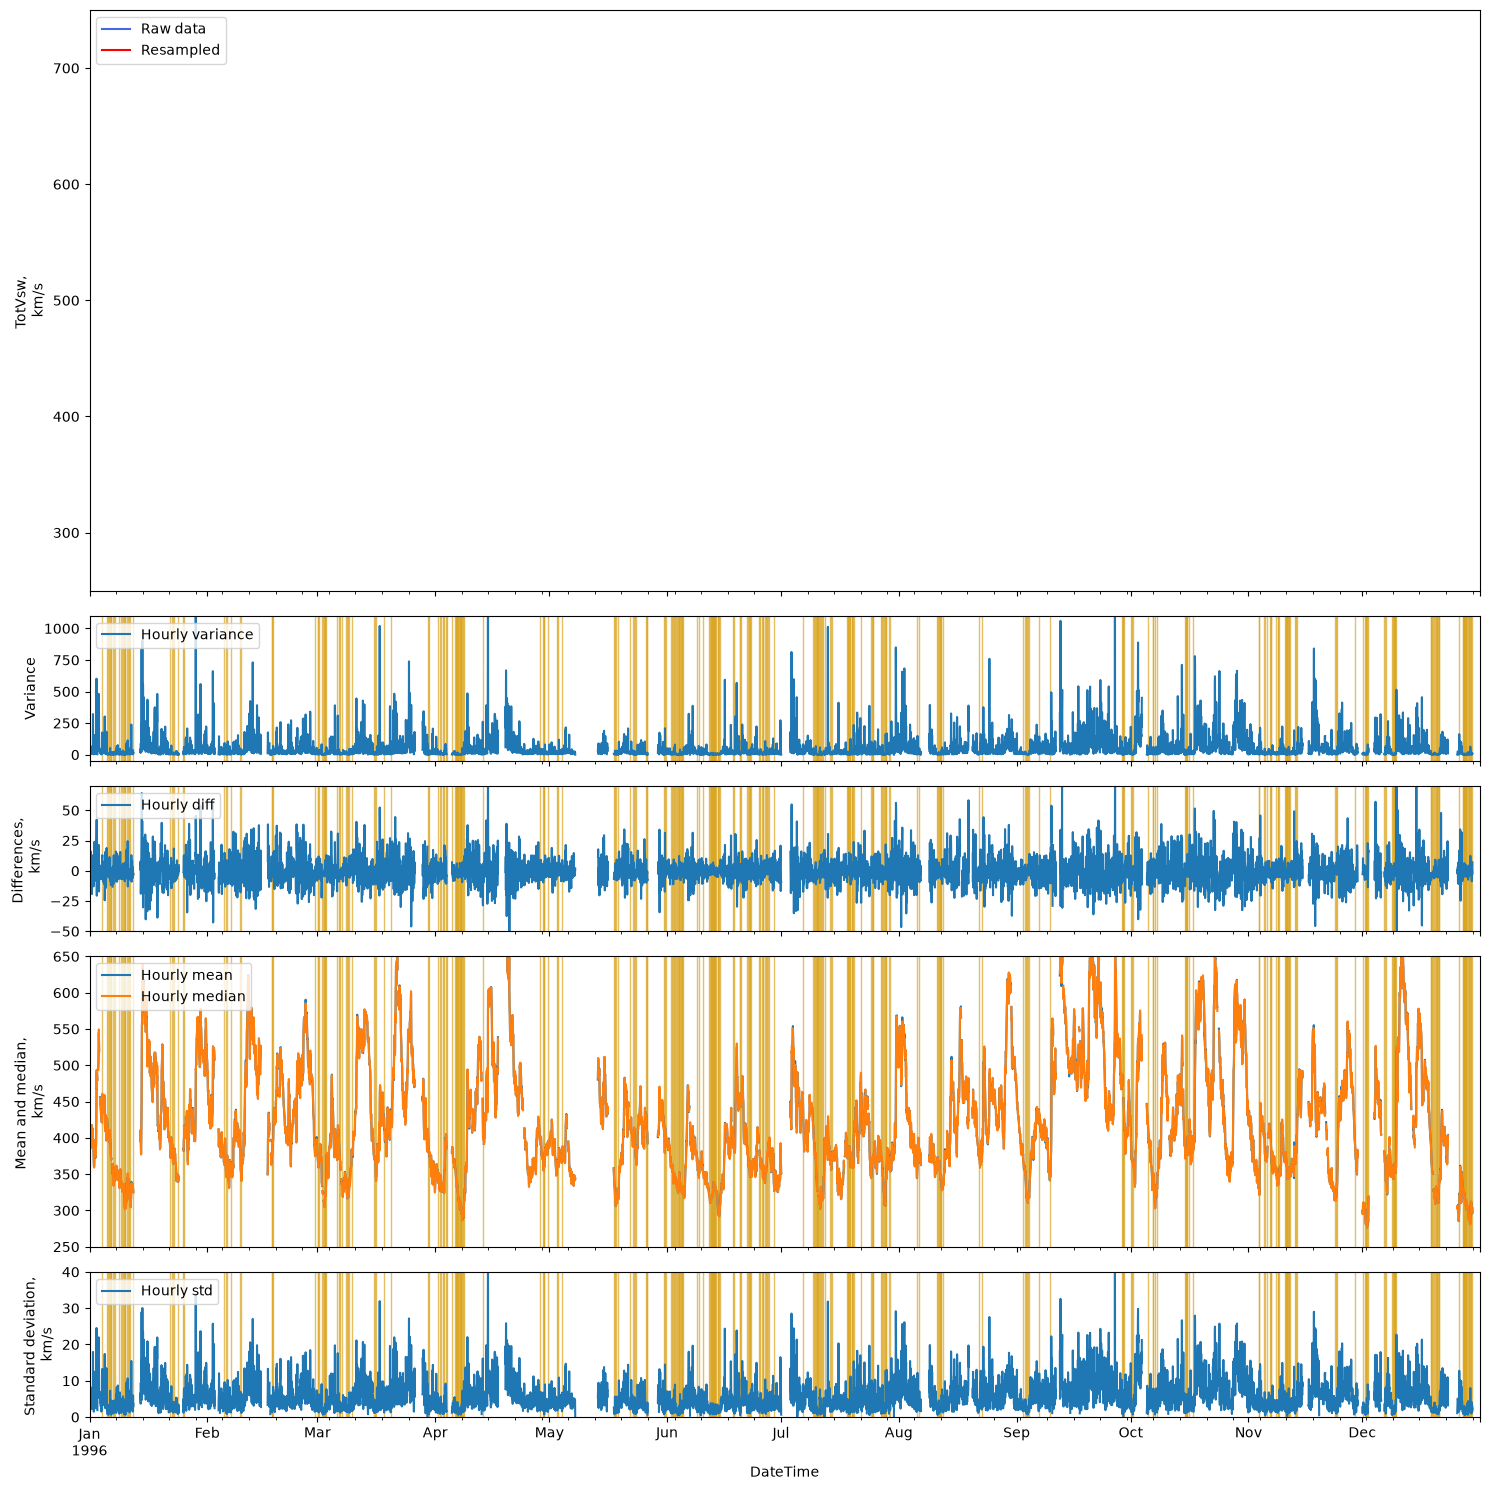

[3600.0, 32400.0, 7200.0, 7200.0, 10800.0, 3600.0, 3600.0, 7200.0, 18000.0, 3600.0, 3600.0, 18000.0, 7200.0, 3600.0, 3600.0, 3600.0, 3600.0, 3600.0, 7200.0, 7200.0, 3600.0, 10800.0, 3600.0, 14400.0, 3600.0, 3600.0, 7200.0, 3600.0, 7200.0, 7200.0, 3600.0, 3600.0, 7200.0, 3600.0, 3600.0, 7200.0, 7200.0, 7200.0, 10800.0, 3600.0, 7200.0, 14400.0, 3600.0, 18000.0, 3600.0, 3600.0, 10800.0, 14400.0, 7200.0, 3600.0, 3600.0, 14400.0, 3600.0, 21600.0, 3600.0, 14400.0, 3600.0, 3600.0, 3600.0, 10800.0, 3600.0, 3600.0, 3600.0, 36000.0, 14400.0, 3600.0, 7200.0, 3600.0, 3600.0, 3600.0, 3600.0, 3600.0, 7200.0, 3600.0, 18000.0, 10800.0, 10800.0, 3600.0, 3600.0, 3600.0, 3600.0, 7200.0, 3600.0, 3600.0, 18000.0, 3600.0, 3600.0, 10800.0, 10800.0, 10800.0, 43200.0, 18000.0, 25200.0, 10800.0, 3600.0, 7200.0, 3600.0, 36000.0, 21600.0, 7200.0, 3600.0, 14400.0, 21600.0, 7200.0, 25200.0, 3600.0, 3600.0, 3600.0, 3600.0, 3600.0, 7200.0, 14400.0, 7200.0, 3600.0, 3600.0, 3600.0, 10800.0, 3600.0, 3600.0, 3600.0, 2160

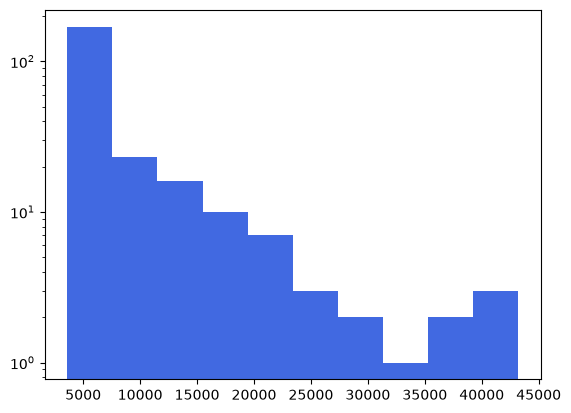

In [235]:
# TotVsw
Variable = "TotVsw"
Unit = "km/s"
YLim = [[250, 750],[-50, 1100],[-50, 70], [250, 650], [0, 40]]
Thres = 5

# # BMag
# Variable = "BMag"
# Unit = "nT"
# YLim = [[-1, 20],[-2, 10],[-5, 6], [0, 15], [0, 3]]
# Thres = 0.1


fig, axs = plt.subplots(5,1, sharex=True, height_ratios=[4,1,1,2, 1], figsize=(15, 15))
rawData = dataTSConcat[1].to_dataframe()
# Resample data - Choose a resample rate that seems accurate to changes in data
# resampledRate1 = resampleMean(rawData, "1h").to_dataframe()
resampledRate1 = rawData.resample("1h").mean()

# Plot
# print(axs[0])
rawData[Variable].plot(color=colour1, label = "Raw data", ax=axs[0])
resampledRate1[Variable].plot(color=colour2, label = "Resampled", ax=axs[0])

# Variance
hourly_var = rawData[Variable].resample("1h").var()
hourly_var.plot(ax=axs[1], label="Hourly variance")

# Differences
hourly_diff = resampledRate1[Variable].diff()
hourly_diff.plot(ax=axs[2], label="Hourly diff")

# Mean/median/standard dev
hourly_mean = rawData[Variable].resample("1h").mean()
hourly_median = rawData[Variable].resample("1h").median()
hourly_mean.plot(ax=axs[3], label="Hourly mean")
hourly_median.plot(ax=axs[3], label="Hourly median")

hourly_std = rawData[Variable].resample("1h").std()
hourly_std.plot(ax=axs[4], label="Hourly std")

# Steadiness defn.
mask_var = hourly_var.between(0, Thres)

values = hourly_var.reindex(mask_var.index)
valid = mask_var.fillna(False).astype(bool) & values.notna()

# print(hourly_var)
# print(mask_var)
# print(values)
# print(valid)

is_start = valid & ~valid.shift(1, fill_value=False)
is_end = valid & ~valid.shift(-1, fill_value=False)

StartsPossible = valid.index[is_start].tolist()
EndsPossible = valid.index[is_end].tolist()

# print(len(StartsPossible))
# print(len(EndsPossible))
# print(StartsPossible)
# print(EndsPossible)

Starts = []
Ends = []
for i in range(len(StartsPossible)):
    # if StartsPossible[i] == EndsPossible[i]:
        # print("Same")
    if StartsPossible[i] != EndsPossible[i]:
        Starts.append(StartsPossible[i])
        Ends.append(EndsPossible[i])

# print(len(Starts))
# print(len(Ends))
# print(Starts)
# print(Ends)

# Starts = StartsPossible.copy()
# Ends = EndsPossible.copy()

YLabel = [ Variable+ ", \n" + Unit, "Variance", "Differences, \n " + Unit, "Mean and median, \n" + Unit, "Standard deviation, \n" + Unit]
for i in range(0,5):
    axs[i].legend(loc="upper left")
    axs[i].set_ylim(YLim[i])
    axs[i].set_ylabel(YLabel[i])
    for j in range(len(Starts)):
        axs[i].axvspan(Starts[j], Ends[j], color="goldenrod", alpha = 0.7)


plt.tight_layout()
plt.show()

TausMin = []
for i in range(len(Starts)):
    TausMin.append((Ends[i] - Starts[i]).total_seconds())

print(TausMin)

plt.hist(TausMin, bins=10, color=colour1)
plt.yscale('log')
plt.show()

# Maximum

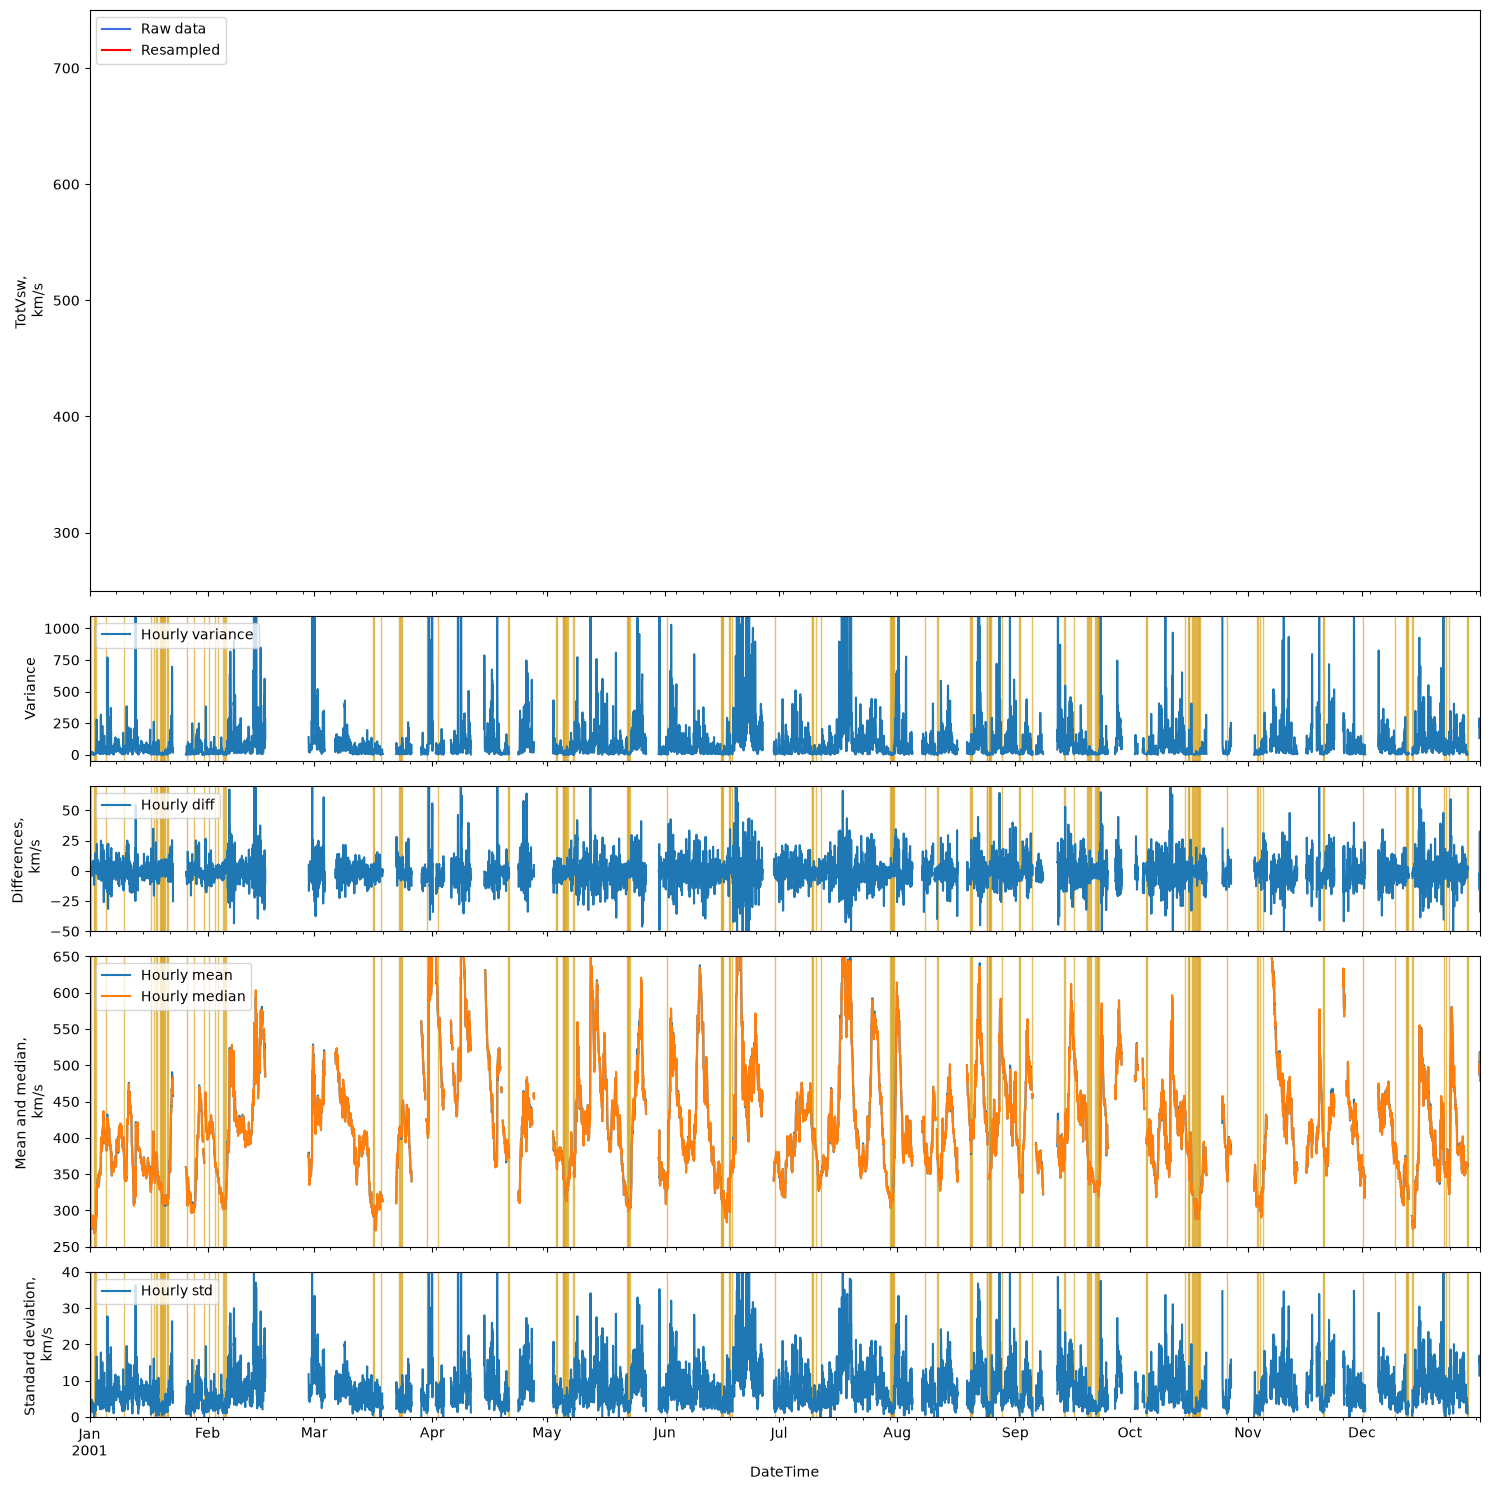

[7200.0, 3600.0, 21600.0, 3600.0, 3600.0, 3600.0, 7200.0, 3600.0, 3600.0, 10800.0, 7200.0, 3600.0, 14400.0, 3600.0, 7200.0, 28800.0, 3600.0, 3600.0, 3600.0, 7200.0, 3600.0, 3600.0, 7200.0, 7200.0, 14400.0, 3600.0, 7200.0, 3600.0, 10800.0, 3600.0, 3600.0, 3600.0, 3600.0, 3600.0, 3600.0, 10800.0, 14400.0, 18000.0, 3600.0, 7200.0, 7200.0, 3600.0, 3600.0, 3600.0, 7200.0, 7200.0, 3600.0, 14400.0, 3600.0, 14400.0, 3600.0, 3600.0, 3600.0, 3600.0, 3600.0, 3600.0, 3600.0, 7200.0, 25200.0, 3600.0, 7200.0, 3600.0, 3600.0, 3600.0, 7200.0, 3600.0, 3600.0, 3600.0, 3600.0, 18000.0, 3600.0, 3600.0, 3600.0, 3600.0, 3600.0, 3600.0, 10800.0, 3600.0, 7200.0, 3600.0, 10800.0, 7200.0, 3600.0, 7200.0, 10800.0, 3600.0, 7200.0, 3600.0, 10800.0, 36000.0, 10800.0, 3600.0, 3600.0, 3600.0, 14400.0, 3600.0, 14400.0, 3600.0, 3600.0, 21600.0, 3600.0, 3600.0, 18000.0, 10800.0, 3600.0, 7200.0, 3600.0, 3600.0, 7200.0, 3600.0]


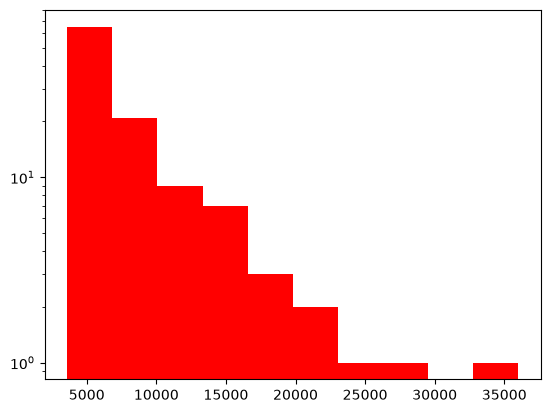

In [236]:
# TotVsw
Variable = "TotVsw"
Unit = "km/s"
YLim = [[250, 750],[-50, 1100],[-50, 70], [250, 650], [0, 40]]
Thres = 5

# # BMag
# Variable = "BMag"
# Unit = "nT"
# YLim = [[-1, 20],[-2, 10],[-5, 6], [0, 15], [0, 3]]
# Thres = 0.1


fig, axs = plt.subplots(5,1, sharex=True, height_ratios=[4,1,1,2, 1], figsize=(15, 15))
rawData = dataTSConcat[2].to_dataframe()
# Resample data - Choose a resample rate that seems accurate to changes in data
# resampledRate1 = resampleMean(rawData, "1h").to_dataframe()
resampledRate1 = rawData.resample("1h").mean()

# Plot
# print(axs[0])
rawData[Variable].plot(color=colour1, label = "Raw data", ax=axs[0])
resampledRate1[Variable].plot(color=colour2, label = "Resampled", ax=axs[0])

# Variance
hourly_var = rawData[Variable].resample("1h").var()
hourly_var.plot(ax=axs[1], label="Hourly variance")

# Differences
hourly_diff = resampledRate1[Variable].diff()
hourly_diff.plot(ax=axs[2], label="Hourly diff")

# Mean/median/standard dev
hourly_mean = rawData[Variable].resample("1h").mean()
hourly_median = rawData[Variable].resample("1h").median()
hourly_mean.plot(ax=axs[3], label="Hourly mean")
hourly_median.plot(ax=axs[3], label="Hourly median")

hourly_std = rawData[Variable].resample("1h").std()
hourly_std.plot(ax=axs[4], label="Hourly std")

# Steadiness defn.
mask_var = hourly_var.between(0, Thres)

values = hourly_var.reindex(mask_var.index)
valid = mask_var.fillna(False).astype(bool) & values.notna()

# print(hourly_var)
# print(mask_var)
# print(values)
# print(valid)

is_start = valid & ~valid.shift(1, fill_value=False)
is_end = valid & ~valid.shift(-1, fill_value=False)

StartsPossible = valid.index[is_start].tolist()
EndsPossible = valid.index[is_end].tolist()

# print(len(StartsPossible))
# print(len(EndsPossible))
# print(StartsPossible)
# print(EndsPossible)

Starts = []
Ends = []
for i in range(len(StartsPossible)):
    # if StartsPossible[i] == EndsPossible[i]:
        # print("Same")
    if StartsPossible[i] != EndsPossible[i]:
        Starts.append(StartsPossible[i])
        Ends.append(EndsPossible[i])

# print(len(Starts))
# print(len(Ends))
# print(Starts)
# print(Ends)

# Starts = StartsPossible.copy()
# Ends = EndsPossible.copy()

YLabel = [ Variable+ ", \n" + Unit, "Variance", "Differences, \n " + Unit, "Mean and median, \n" + Unit, "Standard deviation, \n" + Unit]
for i in range(0,5):
    axs[i].legend(loc="upper left")
    axs[i].set_ylim(YLim[i])
    axs[i].set_ylabel(YLabel[i])
    for j in range(len(Starts)):
        axs[i].axvspan(Starts[j], Ends[j], color="goldenrod", alpha = 0.7)


plt.tight_layout()
plt.show()

TausMax = []
for i in range(len(Starts)):
    TausMax.append((Ends[i] - Starts[i]).total_seconds())

print(TausMax)

plt.hist(TausMax, bins=10, color=colour2)
plt.yscale('log')
plt.show()

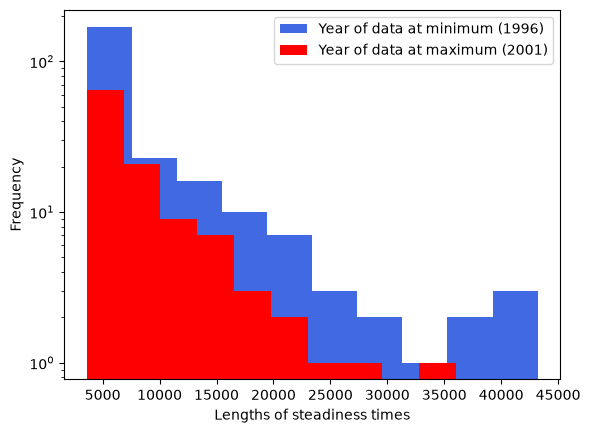

In [245]:
plt.hist(TausMin, bins=10, color=colour1, label = "Year of data at minimum (1996)")
plt.hist(TausMax, bins=10, color=colour2, label = "Year of data at maximum (2001)")
plt.yscale('log')
plt.ylabel("Frequency")
plt.xlabel("Lengths of steadiness times")
plt.legend()

In [17]:
print(len(dataTSConcat[0].to_dataframe()))
print(len(dataTSConcat[1].to_dataframe()))
print(len(dataTSConcat[2].to_dataframe()))

44640
504817
446772


File not saved
File not saved
File not saved
Variance of raw data = 5618.674816153802
Variance of resampled (1h) data = 5534.4558497060625
Variance of resampled (2h) data = 5474.9214019563315


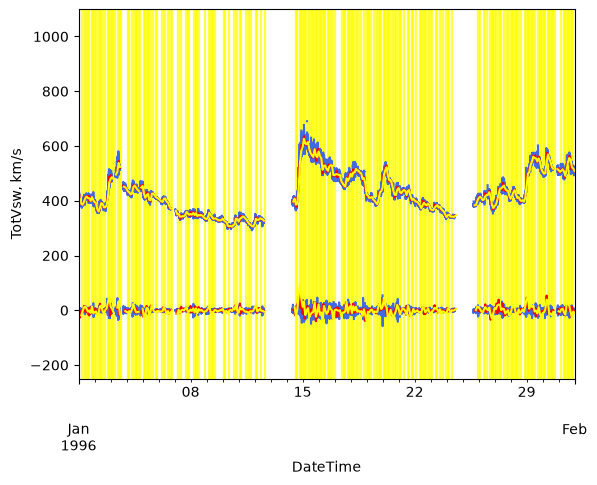

Unique values for rate 2 (2h) = TotVsw
0.0    210
1.0    162
Name: count, dtype: int64
(0 = unsteady, 1 = steady)
File not saved
File not saved
File not saved
Variance of raw data = 6069.068493329572
Variance of resampled (1h) data = 6004.947589093458
Variance of resampled (2h) data = 5985.329851903071


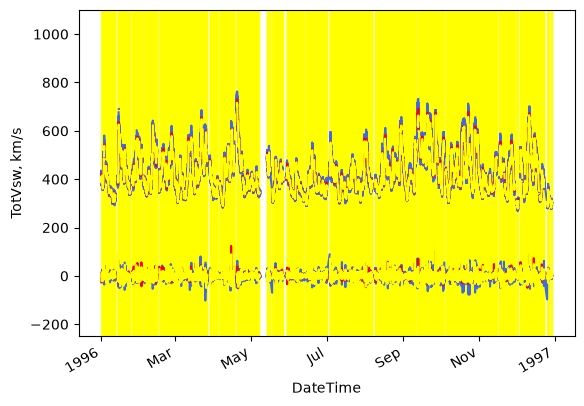

Unique values for rate 2 (2h) = TotVsw
0.0    2407
1.0    1985
Name: count, dtype: int64
(0 = unsteady, 1 = steady)
File not saved
File not saved
File not saved
Variance of raw data = 6369.617372670822
Variance of resampled (1h) data = 6403.0427667026015
Variance of resampled (2h) data = 6424.047336005952


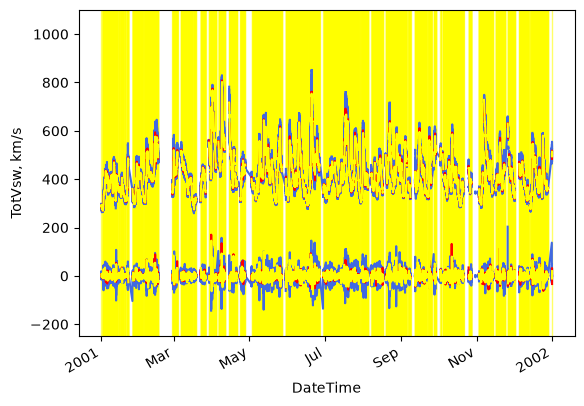

Unique values for rate 2 (2h) = TotVsw
1.0    2287
0.0    2093
Name: count, dtype: int64
(0 = unsteady, 1 = steady)


In [18]:
#Variables
rate1 = "1h"
rate2 = "2h"
ThresholdOfChange = 5 # km/s
Alpha = 0.6

# Columns = ["TotVsw"]#, "Vx_GSE", "Vy_GSE", "Vz_GSE"]
# # # xlim = [Start, End]
# ZoomStart = "1996-01-01 00:00"
# ZoomEnd = "1996-01-01 04:00"
# xlim = [ZoomStart, ZoomEnd]
# # ylim = [250, 700]
# ylim = [-65, 700]

fig, ax = plt.subplots()

# dataCut = [[0,1], [2,13], [14,]]

for i in range(len(dataTSConcat)):
    rawData = dataTSConcat[i]
    # rawDataDF = dataTimeSerieses[i][j].to_dataframe()
    # Resample data - Choose a resample rate that seems accurate to changes in data
    resampledRate1 = resampleMean(rawData, rate1)
    resampledRate2 = resampleMean(rawData, rate2)

    # Plot
    PlotVsw(rawData, Columns=["TotVsw"], Label = "Raw data", Color=colour1)
    PlotVsw(resampledRate1, Columns=["TotVsw"], Label = "Resampled: " + rate1, Color=colour2)
    PlotVsw(resampledRate2, Columns=["TotVsw"], Label = "Resampled: " + rate1, Color=colour3)
    # plt.show()
    # plt.xlim([ZoomStart, ZoomEnd])
        


    # Calculate variance of data
    VarRD = rawData.to_dataframe()["TotVsw"].var()
    print( "Variance of raw data = " + str(VarRD))
    VarRate1 = resampledRate1.to_dataframe()["TotVsw"].var()
    print( "Variance of resampled (" + rate1 + ") data = " + str(VarRate1))
    VarRate2 = resampledRate2.to_dataframe()["TotVsw"].var()
    print( "Variance of resampled (" + rate2 + ") data = " + str(VarRate2))

    # Plot "derivative" of data
    DiffRD = rawData.to_dataframe()["TotVsw"].diff()
    DiffRate1 = resampledRate1.to_dataframe()["TotVsw"].diff()
    DiffRate2 = resampledRate2.to_dataframe()["TotVsw"].diff()
    # print(Diff)
    # print(DiffResampled)

    DiffRD.plot(color=colour1)
    DiffRate1.plot(color=colour2)
    DiffRate2.plot(color=colour3)

    # Diff
    # yOrNot = Diff.where(abs(Diff) < ThresholdOfChange, "notsteady") # .where() replaces where the condition is NOT met (False)
    # DiffSteadyOrNot = DiffSteadyOrNot.where(abs(Diff) > ThresholdOfChange, "steady")
    # # DiffSteadyOrNot = DiffSteadyOrNot.where(abs(Diff) != np.nan, "nan") # get nans back
    DiffRDSteadyOrNot = DiffRD.where(abs(DiffRD) < ThresholdOfChange, 0) # .where() replaces where the condition is NOT met (False)
    DiffRDSteadyOrNot = DiffRDSteadyOrNot.where(abs(DiffRD) > ThresholdOfChange, 1)
    # print(DiffRDSteadyOrNot)

    # DiffResampledSteadyOrNot = DiffResampled.where(abs(DiffResampled) < ThresholdOfChange, "notsteady") # .where() replaces where the condition is NOT met (False)
    # DiffResampledSteadyOrNot = DiffResampledSteadyOrNot.where(abs(DiffResampled) > ThresholdOfChange, "steady")
    # # DiffResampledSteadyOrNot = DiffResampledSteadyOrNot.where(abs(DiffResampled) != np.nan, "nan") # get nans back
    DiffRate1SteadyOrNot = DiffRate1.where(abs(DiffRate1) < ThresholdOfChange, 0) # .where() replaces where the condition is NOT met (False)
    DiffRate1SteadyOrNot = DiffRate1SteadyOrNot.where(abs(DiffRate1) > ThresholdOfChange, 1)
    # print(DiffRate1SteadyOrNot)

    DiffRate2SteadyOrNot = DiffRate2.where(abs(DiffRate2) < ThresholdOfChange, 0) # .where() replaces where the condition is NOT met (False)
    DiffRate2SteadyOrNot = DiffRate2SteadyOrNot.where(abs(DiffRate2) > ThresholdOfChange, 1)
    # print(DiffRate2SteadyOrNot)

    # DiffResampledSteadyOrNotAdj = DiffRate2SteadyOrNot*100
    # DiffResampledSteadyOrNotAdj.plot(color="yellow")

    for y in range(len(DiffRate2SteadyOrNot)): # for each start date (and hopefully each steadiness period)
        if DiffRate2SteadyOrNot.values[y] == 0.0 and DiffRate2SteadyOrNot.index[y] != DiffRate2SteadyOrNot.index[-1]:
            plt.axvspan(DiffRate2SteadyOrNot.index[y], DiffRate2SteadyOrNot.index[y+1], color = colour3, alpha = Alpha) # plot vertical highlighted regions to show where the regions of steadiness are
            # plt.axvspan(starts[y], ends[y], ymin = FirstBaseValue-AbsoluteThreshold, ymax = FirstBaseValue+AbsoluteThreshold, color = "green", alpha = 0.1)
    
    plt.ylabel("TotVsw, km/s")
    plt.ylim([-250, 1100])
    plt.show()

    # print( "unique values = " + str(DiffRate1SteadyOrNot.value_counts()))
    print( "Unique values for rate 2 ("+ rate2+") = " + str(DiffRate2SteadyOrNot.value_counts()))
    print("(0 = unsteady, 1 = steady)")

# Clearer graphs

File not saved
File not saved
File not saved
Variance of raw data = 5618.674816153802
Variance of resampled (1h) data = 5534.4558497060625
Variance of resampled (2h) data = 5474.9214019563315


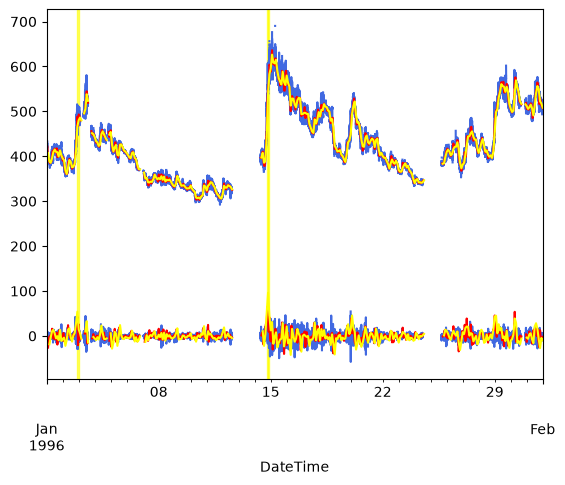

Unique values for rate 2 (2h) = TotVsw
1.0    369
0.0      3
Name: count, dtype: int64
(0 = unsteady, 1 = steady)
File not saved
File not saved
File not saved
Variance of raw data = 5961.970512970401
Variance of resampled (1h) data = 5904.372948550671
Variance of resampled (2h) data = 5884.587311424496


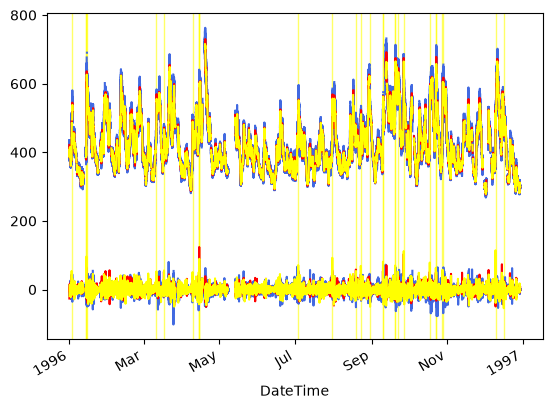

Unique values for rate 2 (2h) = TotVsw
1.0    4365
0.0      27
Name: count, dtype: int64
(0 = unsteady, 1 = steady)
File not saved
File not saved
File not saved
Variance of raw data = 8382.193240894903
Variance of resampled (1h) data = 8278.301994551026
Variance of resampled (2h) data = 8269.00513965665


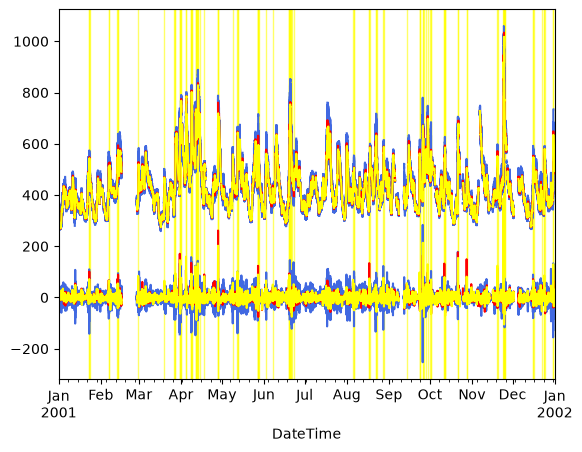

Unique values for rate 2 (2h) = TotVsw
1.0    4283
0.0      97
Name: count, dtype: int64
(0 = unsteady, 1 = steady)


In [218]:
#Variables
rate1 = "1h"
rate2 = "2h"
ThresholdOfChange = 50 # km/s

# Columns = ["TotVsw"]#, "Vx_GSE", "Vy_GSE", "Vz_GSE"]
# # # xlim = [Start, End]
# ZoomStart = "1996-01-01 00:00"
# ZoomEnd = "1996-01-01 04:00"
# xlim = [ZoomStart, ZoomEnd]
# # ylim = [250, 700]
# ylim = [-65, 700]

fig, ax = plt.subplots()

# dataCut = [[0,1], [2,13], [14,]]

for i in range(len(dataTSConcat)):
    rawData = dataTSConcat[i]
    # rawDataDF = dataTimeSerieses[i][j].to_dataframe()
    # Resample data - Choose a resample rate that seems accurate to changes in data
    resampledRate1 = resampleMean(rawData, rate1)
    resampledRate2 = resampleMean(rawData, rate2)

    # Plot
    PlotVsw(rawData, Columns=["TotVsw"], Label = "Raw data", Color=colour1)
    PlotVsw(resampledRate1, Columns=["TotVsw"], Label = "Resampled: " + rate1, Color=colour2)
    PlotVsw(resampledRate2, Columns=["TotVsw"], Label = "Resampled: " + rate1, Color=colour3)
    # plt.show()
    # plt.xlim([ZoomStart, ZoomEnd])
        


    # Calculate variance of data
    VarRD = rawData.to_dataframe()["TotVsw"].var()
    print( "Variance of raw data = " + str(VarRD))
    VarRate1 = resampledRate1.to_dataframe()["TotVsw"].var()
    print( "Variance of resampled (" + rate1 + ") data = " + str(VarRate1))
    VarRate2 = resampledRate2.to_dataframe()["TotVsw"].var()
    print( "Variance of resampled (" + rate2 + ") data = " + str(VarRate2))

    # Plot "derivative" of data
    DiffRD = rawData.to_dataframe()["TotVsw"].diff()
    DiffRate1 = resampledRate1.to_dataframe()["TotVsw"].diff()
    DiffRate2 = resampledRate2.to_dataframe()["TotVsw"].diff()
    # print(Diff)
    # print(DiffResampled)

    DiffRD.plot(color=colour1)
    DiffRate1.plot(color=colour2)
    DiffRate2.plot(color=colour3)

    # DiffSteadyOrNot = Diff.where(abs(Diff) < ThresholdOfChange, "notsteady") # .where() replaces where the condition is NOT met (False)
    # DiffSteadyOrNot = DiffSteadyOrNot.where(abs(Diff) > ThresholdOfChange, "steady")
    # # DiffSteadyOrNot = DiffSteadyOrNot.where(abs(Diff) != np.nan, "nan") # get nans back
    DiffRDSteadyOrNot = DiffRD.where(abs(DiffRD) < ThresholdOfChange, 0) # .where() replaces where the condition is NOT met (False)
    DiffRDSteadyOrNot = DiffRDSteadyOrNot.where(abs(DiffRD) > ThresholdOfChange, 1)
    # print(DiffRDSteadyOrNot)

    # DiffResampledSteadyOrNot = DiffResampled.where(abs(DiffResampled) < ThresholdOfChange, "notsteady") # .where() replaces where the condition is NOT met (False)
    # DiffResampledSteadyOrNot = DiffResampledSteadyOrNot.where(abs(DiffResampled) > ThresholdOfChange, "steady")
    # # DiffResampledSteadyOrNot = DiffResampledSteadyOrNot.where(abs(DiffResampled) != np.nan, "nan") # get nans back
    DiffRate1SteadyOrNot = DiffRate1.where(abs(DiffRate1) < ThresholdOfChange, 0) # .where() replaces where the condition is NOT met (False)
    DiffRate1SteadyOrNot = DiffRate1SteadyOrNot.where(abs(DiffRate1) > ThresholdOfChange, 1)
    # print(DiffRate1SteadyOrNot)

    DiffRate2SteadyOrNot = DiffRate2.where(abs(DiffRate2) < ThresholdOfChange, 0) # .where() replaces where the condition is NOT met (False)
    DiffRate2SteadyOrNot = DiffRate2SteadyOrNot.where(abs(DiffRate2) > ThresholdOfChange, 1)
    # print(DiffRate2SteadyOrNot)

    # DiffResampledSteadyOrNotAdj = DiffRate2SteadyOrNot*100
    # DiffResampledSteadyOrNotAdj.plot(color="yellow")

    for y in range(len(DiffRate2SteadyOrNot)): # for each start date (and hopefully each steadiness period)
        if DiffRate2SteadyOrNot.values[y] == 0.0:
            plt.axvspan(DiffRate2SteadyOrNot.index[y], DiffRate2SteadyOrNot.index[y+1], color = colour3, alpha = Alpha) # plot vertical highlighted regions to show where the regions of steadiness are
            # plt.axvspan(starts[y], ends[y], ymin = FirstBaseValue-AbsoluteThreshold, ymax = FirstBaseValue+AbsoluteThreshold, color = "green", alpha = 0.1)
    
    # ZoomStart = "1996-01-01 00:00"
    # ZoomEnd = "1996-01-01 04:00"
    # XLim = [ZoomStart, ZoomEnd]
    # plt.xlim(XLim)

    plt.show()

    # print( "unique values = " + str(DiffRate1SteadyOrNot.value_counts()))
    print( "Unique values for rate 2 ("+ rate2+") = " + str(DiffRate2SteadyOrNot.value_counts()))
    print("(0 = unsteady, 1 = steady)")

In [58]:
# length = len(Diff)
# Offset = -60
# print(Diff[round(length/2)+ Offset:round(length/2) + Offset+ 20])
# print(DiffSteadyOrNot[round(length/2)+ Offset:round(length/2) + Offset+ 20])

length = len(DiffResampled)
Offset = -60
print(DiffResampled[round(length/2)+ Offset:round(length/2) + Offset+ 20])
print(DiffResampledSteadyOrNot[round(length/2)+ Offset:round(length/2) + Offset+ 20])

DateTime
1996-06-13 13:00:00   -0.017980
1996-06-13 14:00:00   -1.750555
1996-06-13 15:00:00   -0.559265
1996-06-13 16:00:00   -2.635979
1996-06-13 17:00:00    2.457160
1996-06-13 18:00:00   -0.990001
1996-06-13 19:00:00   -3.186328
1996-06-13 20:00:00    1.638167
1996-06-13 21:00:00   -4.515300
1996-06-13 22:00:00   -1.950071
1996-06-13 23:00:00   -2.022839
1996-06-14 00:00:00    1.118670
1996-06-14 01:00:00   -1.085346
1996-06-14 02:00:00    2.727112
1996-06-14 03:00:00    1.433396
1996-06-14 04:00:00   -0.141229
1996-06-14 05:00:00   -3.320692
1996-06-14 06:00:00   -5.207831
1996-06-14 07:00:00   -2.765316
1996-06-14 08:00:00   -4.482521
Freq: h, Name: TotVsw, dtype: float64
DateTime
1996-06-13 13:00:00    1.0
1996-06-13 14:00:00    1.0
1996-06-13 15:00:00    1.0
1996-06-13 16:00:00    1.0
1996-06-13 17:00:00    1.0
1996-06-13 18:00:00    1.0
1996-06-13 19:00:00    1.0
1996-06-13 20:00:00    1.0
1996-06-13 21:00:00    1.0
1996-06-13 22:00:00    1.0
1996-06-13 23:00:00    1.0
1996-06

File not saved
Variance of raw data = 1680.0279445182925
Variance of resampled (1h) data = 1669.6038084496151
Variance of resampled (2h) data = 1657.0670481870395
                     TotVswDev
DateTime                      
1996-06-01 00:00:00        NaN
1996-06-01 00:01:00        NaN
1996-06-01 00:02:00   0.000000
1996-06-01 00:03:00   0.000000
1996-06-01 00:04:00  -2.513142
...                        ...
1996-06-30 23:54:00        NaN
1996-06-30 23:55:00        NaN
1996-06-30 23:56:00        NaN
1996-06-30 23:57:00        NaN
1996-06-30 23:58:00   0.000000

[43199 rows x 1 columns]
Caption: Raw data (royalblue) and data resampled at 1h resample rate (red) and 2h resample rate (yellow).


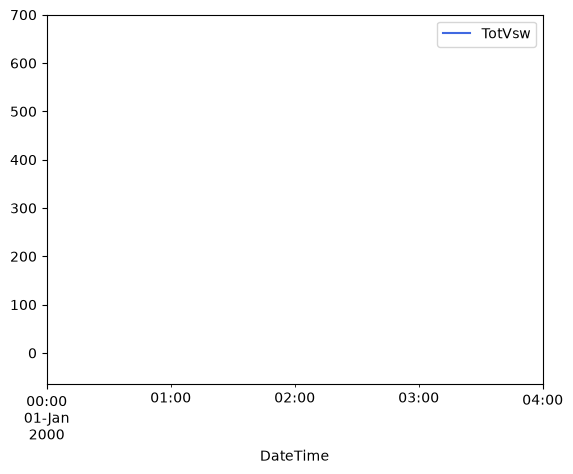

In [ ]:
Columns = ["TotVsw"]#, "Vx_GSE", "Vy_GSE", "Vz_GSE"]
# xlim = [Start, End]
xlim = [ZoomStart, ZoomEnd]
# ylim = [250, 700]
ylim = [-65, 700]
color3 = "yellow"

fig, ax = plt.subplots()
# Plot timeseries with raw data
PlotVsw(dataTimeSerieses[0], Columns=["TotVsw"], XLim = xlim, YLim = ylim, Color = color1, Label = "Raw data")

# Plot timeseries with resampled data
# PlotVsw(resampledTS, Columns=["TotVsw"], XLim = xlim, YLim = ylim, Color = color2, Label = "Resampled at " + rate)
# PlotVsw(resampledTS2, Columns=["TotVsw"], XLim = xlim, YLim = ylim, Color = color3, Label = "Resampled at " + rate2)

# PlotVsw(dataTimeSerieses[0].resample("5min").sum(), Columns=["TotVsw"], XLim = xlim) # .sum() or no?

# Calculate variance of data
dataTimeSeriesVar = dataTimeSerieses[0].to_dataframe()["TotVsw"].var()
print( "Variance of raw data = " + str(dataTimeSeriesVar))
dataTimeSeriesVar = resampled["TotVsw"].var()
print( "Variance of resampled (" + rate + ") data = " + str(dataTimeSeriesVar))
dataTimeSeriesVar = resampled2["TotVsw"].var()
print( "Variance of resampled (" + rate2 + ") data = " + str(dataTimeSeriesVar))

# Plot "derivative" of data
derivative = []
dataToDerive = dataTimeSerieses[0].to_dataframe()["TotVsw"]
# dataToDerive = resampled["TotVsw"]
# dataToDerive = resampled2["TotVsw"]

for i in range(len(dataToDerive)-1):
    y_diff = dataToDerive.values[i+1]-dataToDerive.values[i]
    derivative.append(y_diff)


# derivative10 = []
d = {"TotVswDev": derivative}
derivative = pd.DataFrame(data=d, index=dataToDerive.index[0:-1])
print(derivative)
ax.plot(derivative, markersize=10)
# derivative.plot()
# for j in range(len(derivative)):
#     derivative10.append(derivative[j]*10)

# derivative.plot() # , alpha = 0.5)
# PlotVsw(derivative["TotVswDev"],  XLim = xlim, YLim = ylim, Color = color1, Label = "Raw data")
# plt.plot(dataToDerive.index[0:-1], derivative, color="green")


print("Caption: Raw data ("+str(color1) + ") and data resampled at " + rate + " resample rate ("+str(color2) + ") and "+ rate2 + " resample rate ("+str(color3) + ").")





File not saved


<Axes: xlabel='DateTime'>

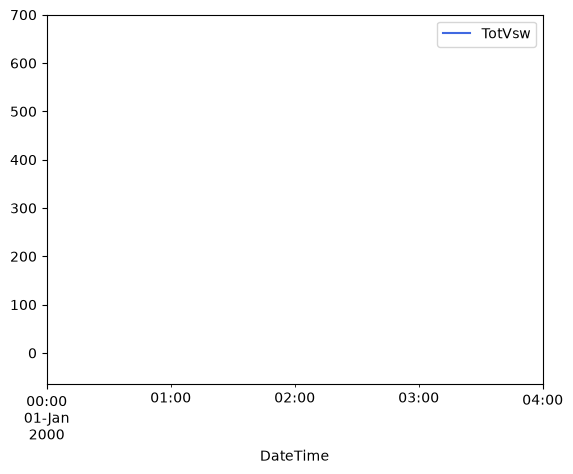

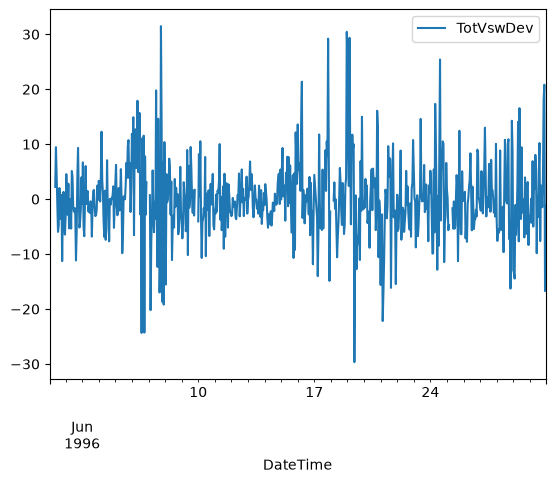

In [ ]:
Columns = ["TotVsw"]#, "Vx_GSE", "Vy_GSE", "Vz_GSE"]
# xlim = [Start, End]
xlim = [ZoomStart, ZoomEnd]
# ylim = [250, 700]
ylim = [-65, 700]
color3 = "yellow"

fig, ax = plt.subplots()
# Plot timeseries with raw data
PlotVsw(dataTimeSerieses[0], Columns=["TotVsw"], XLim = xlim, YLim = ylim, Color = color1, Label = "Raw data")

# Plot "derivative" of data
derivative = []
dataToDerive = resampled["TotVsw"]

for i in range(len(dataToDerive)-1):
    y_diff = dataToDerive.values[i+1]-dataToDerive.values[i]
    derivative.append(y_diff)

d = {"TotVswDev": derivative}
derivative = pd.DataFrame(data=d, index=dataToDerive.index[0:-1])

# ax.plot(derivative)
# plt.plot(derivative)
derivative.plot()




In [61]:
# maskFirst = Data.to_dataframe()[Variable].between(Thres-AbsThres, Thres+AbsThres) # get true/false array of data based on condition of values being between the threshold values


[np.float64(nan), np.float64(nan), np.float64(0.0), np.float64(0.0), np.float64(-2.513142008500438), np.float64(0.0), np.float64(0.0), np.float64(nan), np.float64(nan), np.float64(0.053368969022528745), np.float64(1.1020318513919278), np.float64(-1.6956860460394978), np.float64(2.47746238155014), np.float64(-2.115908970647979), np.float64(-0.1071786654147786), np.float64(-2.833594789879953), np.float64(-0.19977259489195376), np.float64(-0.3062248781183712), np.float64(0.8447922645099197), np.float64(-1.5783687078925368), np.float64(3.1682117150608065), np.float64(1.6645819665489512), np.float64(-5.560019533312129), np.float64(0.0), np.float64(3.1099035887606874), np.float64(0.0), np.float64(nan), np.float64(nan), np.float64(-0.6915984807909012), np.float64(-2.353726231574001), np.float64(1.5569818286068084), np.float64(0.4437111895221051), np.float64(-0.38927792908054926), np.float64(-0.00239920744201072), np.float64(0.3818826031873641), np.float64(0.16397385655983499), np.float64(0.12

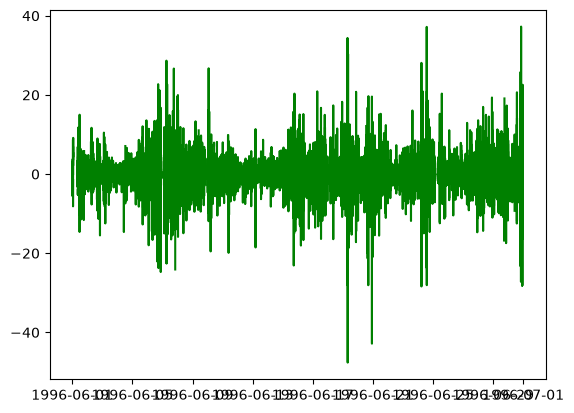

In [ ]:
# Plot "derivative" of data
derivative = []
for i in range(len(dataTimeSerieses[0].to_dataframe())-1):
    y_diff = dataTimeSerieses[0].to_dataframe()["TotVsw"].values[i+1]-dataTimeSerieses[0].to_dataframe()["TotVsw"].values[i]
    derivative.append(y_diff)

print(derivative)
# derivative10 = []

# for j in range(len(derivative)):
#     derivative10.append(derivative[j]*10)

plt.plot(dataTimeSerieses[0].to_dataframe().index[0:-1], derivative, color="green")
# plt.plot(dataTimeSerieses[0].to_dataframe().index[0:-1], derivative10, color="green")

# Plot steady and non-steady regions

# Time series with a lot of steadiness
# Time series with lots of change

# Time series at minimum
# Time series at maximum


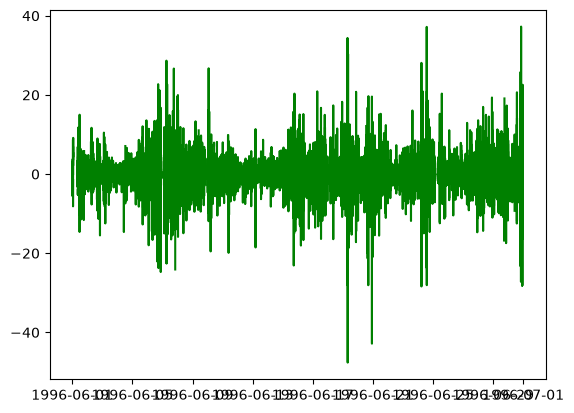

In [ ]:
plt.plot(dataTimeSerieses[0].to_dataframe().index[0:-1], derivative, color="green")
